In [1]:
from PIL import Image, ImageDraw

In [2]:
from matplotlib.pyplot import imshow, figure
# %matplotlib inline

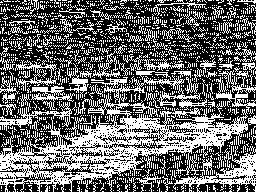

In [3]:
resource_file = open("001!   kog.c1.C", 'rb')

data = resource_file.read()  # Читаем данные

# Смотрим как выглядит то что загрузили
img = Image.frombytes('1', (256, 192), data, "raw")
img

Конечно какая-то внутренняя структура видна, но явно не то что мы хотели видеть. Загружаем файл в дизассемблер:

In [ ]:
RAM:7D00 sub_7D00:
RAM:7D00                 ld      de, 4000h       ; Move o1 <- o2
RAM:7D03                 call    byte_0+7Ch      ; call (cond & uncond)
RAM:7D06                 dec     sp              ; Decrement operand
RAM:7D07                 dec     sp              ; Decrement operand
RAM:7D08                 pop     hl              ; Pop register pair from stack
RAM:7D09                 ld      bc, 20h ; ' '   ; Move o1 <- o2
RAM:7D0C                 add     hl, bc          ; Add <reg> to A
RAM:7D0D                 ld      b, 0            ; Move o1 <- o2
RAM:7D0F
RAM:7D0F loc_7D0F:                               ; CODE XREF: sub_7D00+19j
RAM:7D0F                                         ; sub_7D00+24j
RAM:7D0F                 ld      a, (hl)         ; Move o1 <- o2
RAM:7D10                 or      a               ; Or with accumulator
RAM:7D11                 ret     z               ; Return (cond & uncond)
RAM:7D12                 ld      c, a            ; Move o1 <- o2
RAM:7D13                 inc     hl              ; Increment operand
RAM:7D14                 ldir                    ; Transfer data (DE)->(HL) until byte
RAM:7D14                                         ; counter is zero, increment destination
RAM:7D14                                         ; and source addresses
RAM:7D16                 ld      a, (hl)         ; Move o1 <- o2
RAM:7D17                 inc     hl              ; Increment operand
RAM:7D18                 and     a               ; And with accumulator
RAM:7D19                 jr      z, loc_7D0F     ; Jump relative (conditional & unconditional)
RAM:7D1B                 push    hl              ; Push register pair onto stack
RAM:7D1C                 dec     de              ; Decrement operand
RAM:7D1D                 ld      h, d            ; Move o1 <- o2
RAM:7D1E                 ld      l, e            ; Move o1 <- o2
RAM:7D1F                 inc     de              ; Increment operand
RAM:7D20                 ld      c, a            ; Move o1 <- o2
RAM:7D21                 ldir                    ; Transfer data (DE)->(HL) until byte
RAM:7D21                                         ; counter is zero, increment destination
RAM:7D21                                         ; and source addresses
RAM:7D23                 pop     hl              ; Pop register pair from stack
RAM:7D24                 jr      loc_7D0F        ; Jump relative (conditional & unconditional)
RAM:7D24 ; End of function sub_7D00
RAM:7D24 ; ---------------------------------------------------------------------------
RAM:7D26                 db    1
RAM:7D27                 db    0
RAM:7D28                 db  0Fh
RAM:7D29                 db    7
RAM:7D2A                 db    2
RAM:7D2B                 db 0A9h ; й
...

Проанализировав код процедуры, получаем следующий алгоритм:

Есть исходная область памяти, есть целевая область памяти.

1. Смотрим текущий байт. Если он равен 0 - выходим (блок от `7D0F` до `7D11`)
2. Если не 0, копируем это количество байт в другую область памяти (блок от `7D12` до `7D14`)
3. Смотрим следующий байт. Если он равен 0, возвращаемся на шаг 1 (блок от `7D16` до `7D19`)
4. Если не 0, дублируем последний скопированный байт в соответствии со значением байта (блок от `7D1B` до `7D23`)
5. Возвращаемся на шаг 1

По сути картинка сжата одним из вариантов [RLE](https://ru.wikipedia.org/wiki/Кодирование_длин_серий). При переводе процедуры распаковки на Python получаем следующий код:

In [4]:
def unrle_data(data):
    s = bytearray()
    i = 0
    while True:
        a = data[i]
        if a == 0:
            return bytes(s)
        
        i += 1
        s += data[i:i+a]  # ldir
        i += a
        
        a = data[i]
        i += 1
        if a != 0:
            s += s[-1:] * a  # размножаем последний скопированный байт

Загружаем данные заново, распаковываем, и смотрим что получилось:

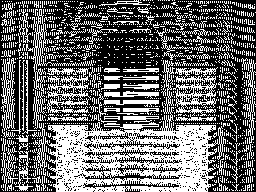

In [5]:
resource_file.seek(0x26)  # Пропускаем код распаковки
data = resource_file.read()  # Читаем данные заново

data = unrle_data(data + b'\0')  # Распаковываем данные 
img = Image.frombytes('1', (256, 192), data, "raw")
img

Получили более-менее "красивую" регулярную картинку. Чтобы все-таки получить правильную картинку нужно выполнить еще один шаг.
Дело в том, что в видеобуфере ZX Spectrum байты хранятся не подряд построчно, а распределены довольно хитрым образом:

* В целом картинка разбита на 3 блока по `32*192/3 = 2048` байт
* Каждый блок разделен на 8 горизонтальных рядов по 8 пикселей в каждом. Сначала в памяти располагаются первые строки каждого ряда, потом вторые строки, и т.д.
* Каждая пиксельная строка состоит из 32 колонок по 8 бит. Каждый бит кодирует один пиксель, 1 означает использование цвета пера (`INK`), 0 означает цвет фона (`PAPER`)

Дальше в памяти идет блок байт, кодирующих цвета (атрибуты) отдельных знакомест (квадратов 8x8 пикселей), один байт кодирует цвета (цвет фона, цвет пера, яркость, мигание) для отдельного знакоместа. Этот блок данных занимает `32*24 = 768` байт.

Чтобы увидеть это все на практике, можно посмотреть на процесс загрузки титульного экрана какой-нибудь игры, к примеру вот загрузка экрана игры Commando: https://youtu.be/nTUvJtIfWFE?t=31s (фрагмент с 0.31 по 1.12).

Пишем функцию для преобразования порядка байт в более человеческий (последовательный):

In [6]:
def fix_screen_byte_order(data):
    screen = [0 for i in range(32*192)]
    for i, b in enumerate(data[:len(screen)]):
        column = i & 0x1F  # Номер колонки (от 0 до 31)
        i >>= 5
        row = i & 7  # Номер ряда в символах (от 0 до 7)
        i >>= 3
        line = i & 7  # Номер пиксельной строки в ряду (от 0 до 7)
        i >>= 3
        block = i  # Номер блока (фактически - от 0 до 2)
        screen[block*32*8*8 + row*32*8 + line*32 + column] = b
    return bytes(screen)

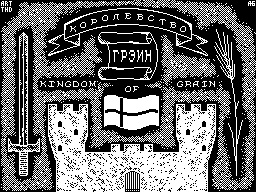

In [7]:
screen = fix_screen_byte_order(data)  # Исправляем порядок байт
img = Image.frombytes('1', (256, 192), screen, "raw")  # Смотрим что получилось
img

Уже что-то. Дальше нам нужно декодировать блок атрибутов и применить цвета к нашей черно-белой картинке.

In [8]:
def decode_attr(attr: int):
    '''
    Декодируем код атрибута
    
    7 бит отвечает за мигание (мы его учитывать не будем)
    6 бит - яркость
    5, 4, 3 биты - цвет фона (PAPER)
    2, 1, 0 биты - цвет "пера" (INK)
    '''
    
    return dict(
        flash=attr >> 7,
        bright=attr >> 6 & 1,
        paper=attr >> 3 & 7,
        ink=attr & 7
    )

In [9]:
def triple2rgb(color, bright):
    '''
    Преобразовываем тройку бит (значения от 0 до 7) в тройку значений яркости цветовых составляющих (Red, Green, Blue)
    В цветовой тройке:
    2 бит соответствует зеленому
    1 бит - красному
    0 бит - синему
    (соответствие подобрано опытным путем)
    '''
    
    blue = 128 * (color & 1) * (bright + 1)
    red = 128 * (color >> 1 & 1) * (bright + 1)
    green = 128 * (color >> 2 & 1) * (bright + 1)
    
    # Выходные данные - RGB-тройка, каждая составляющая принимает одно из трех значений: 0, 127, 255
    return tuple(item - 1 if item else item for item in (red, green, blue))

In [10]:
def fix_colors(image: Image, attr_values: bytes) -> Image:
    '''
    Исправляем цвета картинки. На входе - исходная черно-белая картинка, блок атрибутов, ширина картинку
    '''
    new_image = img.convert('RGB')
    drawer = ImageDraw.Draw(new_image)
    pix = image.load()
    w = new_image.width // 8  # Ширина картинки в знакоместах
    for x in range(new_image.width):
        for y in range(new_image.height):
            attr = attr_values[x // 8 + y // 8 * w]
            decoded = decode_attr(attr)
            color = decoded['ink'] if pix[x, y] else decoded['paper']
            drawer.point((x, y), triple2rgb(color, decoded['bright']))
    return new_image

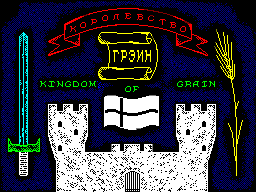

In [11]:
attributes = data[-32*24:]  # Последние 32*24 байт кодируют цвета знакомест (атрибуты)
img = fix_colors(img, attributes)
img

In [12]:
# Сохраняем результат изображения, закрываем исходный файл
img.save('title.png')
resource_file.close()

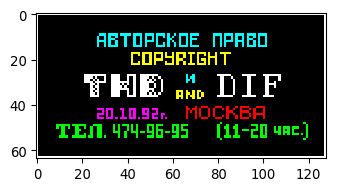

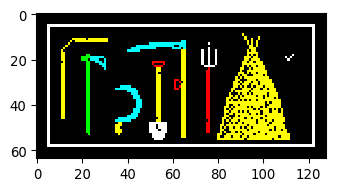

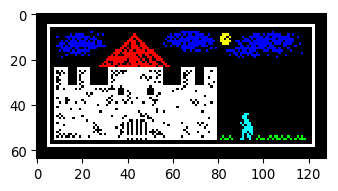

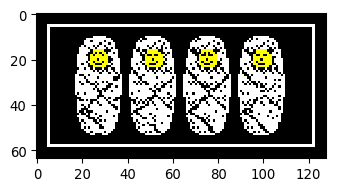

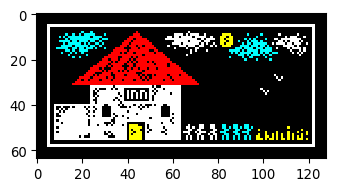

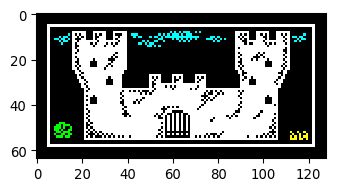

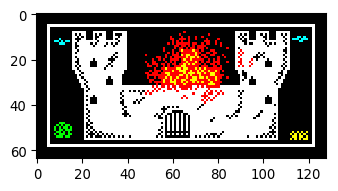

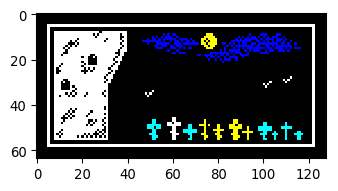

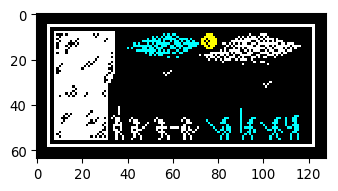

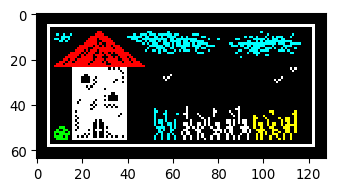

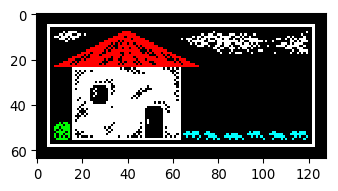

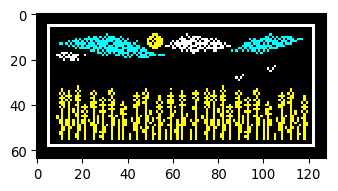

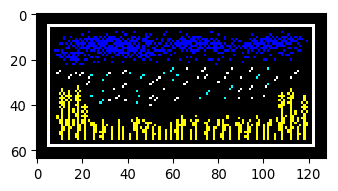

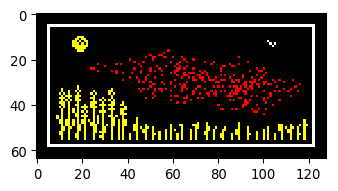

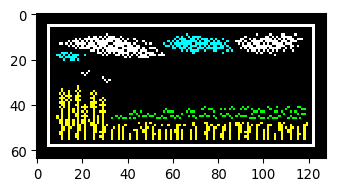

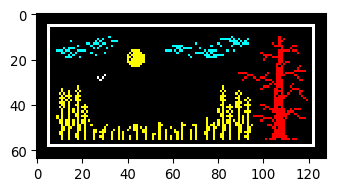

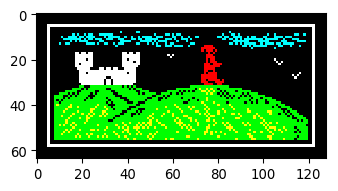

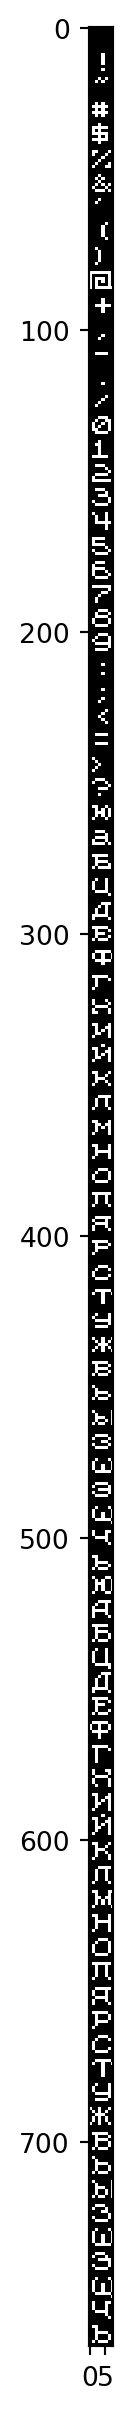

In [13]:
with open('002!   kog.c2.c', 'rb') as resource_file:
    i = 0
    try:
        while True:
            if i == 5:
                skip = resource_file.read(0xACB)
            skip = resource_file.read(6)
            data = resource_file.read(128*64//8)
            img = Image.frombytes('1', (128, 64), data, "raw")
            attr = resource_file.read(128)
            img = fix_colors(img, attr)
            figure(num=None, figsize=(4, 2), dpi=96)
            imshow(img)
            i += 1
            img.save('%d.png' % i)
    except ValueError:
        pass
    
    resource_file.seek(0xC468-0xA6FF+256)
    data = resource_file.read(1024-256)
    img = Image.frombytes('1', (8, len(data)), data, 'raw')
    figure(num=None, figsize=(2, 16), dpi=192)
    imshow(img)
    img.save('font.png')

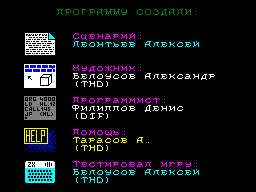

In [14]:
with open("002!   kog.c2.c", 'rb') as resource_file:
    resource_file.seek(0xBDC3 - 0xA6FF)
    data = resource_file.read()
    data = unrle_data(data)
    attr = data[-32*24:]
    screen = fix_screen_byte_order(data)
    img = Image.frombytes('1', (256, 192), screen, "raw")
    img = fix_colors(img, attr)
    img.save('credits.png')

img